# CarRacing RL Competition — Reinforcement_material
T4 GPU를 선택하고 순서대로 실행하세요. 목표는 공개 20트랙 평균 >=950입니다. 매 프레임 시간 비용 때문에 전 타일 방문 시 500프레임이면 950점입니다. [Beta-PPO 참고 논문](https://arxiv.org/abs/2111.02202)

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 1. 코드 준비
공식 합본 ZIP을 업로드합니다. 정책은 RGB에서 유래한 관측만 사용합니다.

In [2]:
import os, sys, subprocess, hashlib, zipfile, shutil
from pathlib import Path
from google.colab import drive, files

os.environ['SDL_VIDEODRIVER'] = 'dummy'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
root = Path('/content/beta_ppo_official')
run = Path('/content/drive/MyDrive/CarRacing/Reinforcement_material_beta_s42_stall_steer_v3')
zip_path = Path('/content/carracing_competition.zip')
if not zip_path.is_file():
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('공식 ZIP 하나를 선택하세요.')
    zip_path.write_bytes(next(iter(uploaded.values())))
manifest = {'agents/actor_critic.py': 'd25aa847bf5d9c0c9803c0016849f2d9bae410caeecf0d943fba8fd695c02037', 'agents/base.py': 'f183f1e46745a9abb5e7f0fc88a08be134104f599326f57ac9bc7f63a324e743', 'agents/dqn.py': '37d7168f7bcb252eff69aab561e85c5ab3d73f01007f6ab95ab00d60fd0d5415', 'agents/__init__.py': '215cd1e434eaf15791c2c826380c5eab6844225ce7b5b9e134894eefd52edc59', 'buffers.py': '59b576518a9997a51f2811f00c8c900394dba24f45d6fb8eaa05f0324da018f1', 'check_submission.py': '7a62312300656f891d1aeffdcab249c501de0153567138f027e8491998763a02', 'envs.py': 'ceee2d847af1a3a498c6b7f0f83f3561b24ac22e53de8bded43c97a15af645d0', 'evaluate.py': '219d4c3ded5b8624d8e4f69d3c71e27145aed6b9eb20dc0ef8b0f9c2355c2574', 'export.py': 'dbd9fe51c3046d2d5a458ad8ea464e99cde777c13be7d8406bf2f667b05f8a6f', 'networks.py': '05c5c6dbd6f4ce2fbfe2a71ef18f84d175ff7a7ff36540c9172f750f27b2b3d8', 'README.md': 'f4b928b8d1ae7f907d21670f5d5c0fe6050845f056ab567ab7b18968608a86b0', 'requirements.txt': 'b38b63f4f8d53b8edce022020a26886d6f079d3484d16d3eb630e530fd11b9b7', 'train.py': '579b46fbf559233490bd3e0949b29880dfe564d890e15c37ba99db7a2344b6b1'}
with zipfile.ZipFile(zip_path) as archive:
    for name, digest in manifest.items():
        data = archive.read('carracing_competition/' + name)
        if hashlib.sha256(data).hexdigest() != digest:
            raise ValueError(f'공식 배포본 버전을 확인하세요: {name}')
        dest = root / name
        dest.parent.mkdir(parents=True, exist_ok=True)
        dest.write_bytes(data)
os.chdir(root)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)

Saving carracing_competition.zip to carracing_competition.zip


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], returncode=0)

In [3]:
%%writefile agents/beta_ppo.py
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Beta
from agents.base import Agent
from networks import CNNEncoder


def controls(sample):
    steer, pedal = (2 * sample - 1).unbind(-1)
    return torch.stack((steer, pedal.relu(), (-pedal).relu()), dim=-1)


class BetaPolicy(nn.Module):
    def __init__(self, shape):
        super().__init__()
        self.encoder = CNNEncoder(shape, feature_dim=256)
        self.actor = nn.Linear(256, 4)
        self.progress = nn.Linear(258, 1)
        self.critic = nn.Linear(256, 1)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        # Mild forward exploration at initialization. All four biases are trainable.
        with torch.no_grad():
            self.actor.bias.copy_(torch.tensor([0., 1.5, 0., -0.5]))

    def heads(self, features):
        alpha, beta = (1 + F.softplus(self.actor(features))).chunk(2, dim=-1)
        return alpha, beta, self.critic(features).squeeze(-1)

    def parameters_at(self, obs):
        return self.heads(self.encoder(obs))

    def forward(self, obs):
        alpha, beta, _ = self.parameters_at(obs)
        return controls(alpha / (alpha + beta))


class BetaPPO(Agent):
    name = "beta_ppo"
    default_config = dict(continuous=True, lr=0.00025, gamma=0.99, gae_lambda=0.95,
                          rollout=512, epochs=4, batch=64, clip=0.2, reward_scale=0.1,
                          stall_steer_cost=0.4, progress_coef=0.05, entropy_coef=0.005, target_kl=0.025)

    def __init__(self, obs_shape, action_space, config, device):
        super().__init__(obs_shape, action_space, config, device)
        if not self.continuous:
            raise ValueError("beta_ppo requires continuous=True")
        self.net = BetaPolicy(obs_shape).to(device)
        self.optim = torch.optim.Adam(self.net.parameters(), lr=self.cfg["lr"], eps=1e-5)
        self.buffer = []
        self.no_gain_steps = 0

    @torch.no_grad()
    def act(self, obs, deterministic=False):
        x = torch.as_tensor(obs, device=self.device)[None]
        if deterministic:
            return self.net(x)[0].cpu().numpy()
        alpha, beta, value = self.net.parameters_at(x)
        dist = Beta(alpha, beta)
        sample = dist.sample()
        self.pending = (sample[0].cpu().numpy(), dist.log_prob(sample).sum().item(), value.item())
        return controls(sample)[0].cpu().numpy()

    def step(self, obs, action, reward, next_obs, terminated, truncated):
        self.no_gain_steps = self.no_gain_steps + 1 if reward <= 0 else 0
        excess = max(0., abs(float(action[0])) - 0.5)
        penalty = self.cfg["stall_steer_cost"] * excess if self.no_gain_steps >= 8 else 0.
        self.buffer.append((obs, *self.pending, reward, next_obs, terminated, truncated, penalty))
        if terminated or truncated:
            self.no_gain_steps = 0
        if len(self.buffer) < self.cfg["rollout"]:
            return {}
        metrics = self.update()
        self.buffer.clear()
        return metrics

    def update(self):
        c = self.cfg
        obs, samples, logs, values, rewards, successors, terms, truncs, penalties = zip(*self.buffer)
        def tensor(seq, dtype):
            return torch.as_tensor(np.stack(seq), device=self.device, dtype=dtype)
        x = tensor(obs, torch.uint8)
        u = tensor(samples, torch.float32)
        old_log = tensor(logs, torch.float32)
        with torch.no_grad():
            next_x = tensor(successors, torch.uint8)
            next_values = torch.cat([self.net.parameters_at(chunk)[2] for chunk in next_x.split(c["batch"])]).cpu().numpy()
        advantages = np.empty(len(rewards), dtype=np.float32)
        tail = 0.
        for i in reversed(range(len(rewards))):
            delta = (rewards[i] - penalties[i]) * c["reward_scale"] - values[i]
            if not terms[i]:
                delta += c["gamma"] * next_values[i]
            carry = 0. if terms[i] or truncs[i] else tail
            tail = delta + c["gamma"] * c["gae_lambda"] * carry
            advantages[i] = tail
        adv = tensor(advantages, torch.float32)
        targets = adv + tensor(values, torch.float32)
        adv = (adv - adv.mean()) / (adv.std(unbiased=False) + 1e-8)
        gain = tensor(np.asarray(rewards) > 0, torch.float32)
        losses = []
        for epoch in range(c["epochs"]):
            divergences = []
            for idx in torch.randperm(len(x), device=self.device).split(c["batch"]):
                features = self.net.encoder(x[idx])
                a, b, pred = self.net.heads(features)
                dist = Beta(a, b)
                log_ratio = dist.log_prob(u[idx]).sum(-1) - old_log[idx]
                ratio = log_ratio.exp()
                clipped = ratio.clamp(1-c["clip"], 1+c["clip"])
                policy_loss = -torch.minimum(ratio * adv[idx], clipped * adv[idx]).mean()
                loss = policy_loss + 0.5 * F.mse_loss(pred, targets[idx])
                progress_logits = self.net.progress(torch.cat((features, u[idx]), dim=1)).squeeze(-1)
                loss += c["progress_coef"] * F.binary_cross_entropy_with_logits(progress_logits, gain[idx])
                loss -= c["entropy_coef"] * dist.entropy().sum(-1).mean()
                self.optim.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), 0.5, error_if_nonfinite=True)
                self.optim.step()
                losses.append(loss.item())
                divergences.append((ratio.detach() - 1 - log_ratio.detach()).mean().item())
            if np.mean(divergences) > c["target_kl"]:
                break
        return dict(loss=float(np.mean(losses)), kl=float(np.mean(divergences)),
                    gas=float((2*u[:,1]-1).relu().mean()), brake=float((1-2*u[:,1]).relu().mean()))

    def export_policy(self):
        return self.net

    def state_dict(self):
        return dict(net=self.net.state_dict(), optim=self.optim.state_dict())

    def load_state_dict(self, state):
        self.net.load_state_dict(state["net"])
        self.optim.load_state_dict(state["optim"])
        self.buffer.clear()  # A resumed environment starts a new episode.

Writing agents/beta_ppo.py


In [4]:
# 실제 학습 전, 합성 관측으로 PPO 업데이트와 제출 정책 출력을 점검합니다.
import torch, gymnasium as gym, numpy as np
from agents.beta_ppo import BetaPPO
space = gym.spaces.Box(np.array([-1,0,0], np.float32), np.ones(3, np.float32))
test = BetaPPO((4,96,96), space, dict(rollout=4, batch=2, epochs=1), 'cpu')
obs = np.zeros((4,96,96), dtype=np.uint8)
for i in range(4):
    action = test.act(obs)
    assert space.contains(action) and action[1] * action[2] == 0
    stats = test.step(obs, action, 1., obs, i==1, i==3)
assert np.isfinite(stats['loss'])
np.testing.assert_allclose(test.act(obs, True), test.export_policy()(torch.from_numpy(obs)[None]).detach().numpy()[0])
print('합성 입력 검사 통과', stats)

합성 입력 검사 통과 {'loss': 0.047078803181648254, 'kl': 3.725290298461914e-08, 'gas': 0.3430151641368866, 'brake': 0.03479151427745819}


## 2. 학습
30만 원본 프레임. 검증 seed 500–504로 best.pt를 선택합니다. 보조 학습은 선택한 행동 뒤 양의 보상이 발생했는지 예측합니다. 진단용 이탈 추정은 행동 선택에 쓰지 않습니다.

In [5]:
cmd = [sys.executable, '-u', 'train.py', '--agent', 'beta_ppo', '--seed', '42',
       '--budget', '300000', '--eval-every', '25000', '--run-dir', str(run)]
if (run/'latest.pt').exists():
    cmd.append('--resume')
elif run.exists() and any(run.iterdir()):
    raise RuntimeError('체크포인트가 없는 기존 run입니다. 새 전용 경로를 지정하세요.')
subprocess.run(cmd, check=True)

CompletedProcess(args=['/usr/bin/python3', '-u', 'train.py', '--agent', 'beta_ppo', '--seed', '42', '--budget', '300000', '--eval-every', '25000', '--run-dir', '/content/drive/MyDrive/CarRacing/Reinforcement_material_beta_s42_stall_steer_v3'], returncode=0)

## 3. 학습 곡선

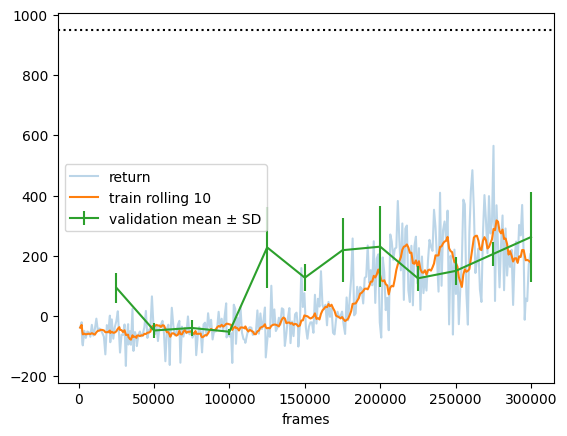

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
train = pd.read_csv(run/'train.csv')
val = pd.read_csv(run/'eval.csv')
ax = train.plot(x='frames', y='return', alpha=.3)
ax.plot(train.frames,train['return'].rolling(10,min_periods=1).mean(),label='train rolling 10')
ax.errorbar(val.frames,val.score,yerr=val['std'],label='validation mean ± SD')
ax.axhline(950,color='black',linestyle=':')
ax.legend()
plt.show()

## 4. 평가 및 주행 영상
제출용 ONNX로 공개 seed 1000–1009를 달립니다. 96×96 원본 관측 한 장이 영상 한 프레임이며 CSV의 video_s와 대응합니다. 차 옆의 녹색 비율로 이탈·복귀를 추정합니다. 경계와 커브에서는 영상을 함께 확인하세요. image_change는 화면 변화량이며 실제 속도 단위와 다릅니다.

In [7]:
import json
from evaluate import load_agent
from export import export, verify
team = 'Reinforcement_material'
onnx_path = run / (team + '_beta.onnx')
agent = load_agent(str(run/'best.pt'), torch.device('cpu'))
export(agent, str(onnx_path))
rate, steps = verify(agent, str(onnx_path))
print(f'행동 일치율 {rate:.1%} ({steps} steps)')
if rate < .95:
    raise RuntimeError('행동 일치율 기준 미달')

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


행동 일치율 100.0% (250 steps)


In [8]:
import csv
from collections import deque
from contextlib import closing
from moviepy import ImageSequenceClip
import check_submission as grader

out = run / 'diagnostics'
out.mkdir(exist_ok=True)
sess, cfg = grader.load_policy(str(onnx_path))
def grass_fraction(rgb):
    # Sample strips beside the car, clear of its sprite and dashboard.
    left = rgb[66:76, 39:43].astype(int)
    right = rgb[66:76, 53:57].astype(int)
    red, green, blue = np.concatenate((left,right),axis=1).transpose(2,0,1)
    return float(((green > red + 25) & (green > blue + 25)).mean())

def record_seed(seed):
    env = grader.HideScoreText(gym.make('CarRacing-v3', continuous=True))
    rows, images = [], []
    hints = deque(maxlen=5)
    total = 0.
    last_gain = decision = 0
    off = done = False
    try:
        obs, _ = env.reset(seed=seed)
        stack = deque([obs]*cfg['n_stack'], maxlen=cfg['n_stack'])
        while not done:
            raw = sess.run(['action'], {'frames': np.stack(stack)[None]})[0]
            action = grader.to_env_action(raw, cfg, env)
            decision += 1
            for _ in range(cfg['frame_skip']):
                before = obs
                obs, reward, term, trunc, _ = env.step(action)
                frame = len(rows)+1
                total += reward
                if reward > 0:
                    last_gain = frame
                grass = grass_fraction(obs)
                hints.append(grass)
                previous = off
                if len(hints)==5 and frame >= 60:  # ignore startup camera zoom
                    if min(hints) > .65:
                        off = True
                    elif max(hints) < .25:
                        off = False
                event = ('grass_entry' if off else 'road_return') if off != previous else ''
                motion = np.abs(obs[:80].astype(int)-before[:80].astype(int)).mean()
                rows.append(dict(seed=seed,frame=frame,video_s=(frame-1)/50,
                    decision=decision,steer=action[0],gas=action[1],brake=action[2],
                    reward=reward,score=total,frames_since_gain=frame-last_gain,
                    image_change=motion,grass_fraction=grass,offroad_hint=int(off),
                    event=event,terminated=term,truncated=trunc))
                images.append(obs.copy())
                done = term or trunc
                if done:
                    break
            stack.append(obs)
    finally:
        env.close()
    stem = out/f'seed_{seed}'
    pd.DataFrame(rows).to_csv(stem.with_suffix('.csv'),index=False)
    with closing(ImageSequenceClip(images, fps=50)) as clip:
        clip.write_videofile(str(stem.with_suffix('.mp4')), codec='libx264', audio=False,logger=None)
    return dict(seed=seed,score=total,frames=len(rows),grass_entries=sum(r['event']=='grass_entry' for r in rows),
                grass_frames=sum(r['offroad_hint'] for r in rows),max_frames_without_gain=max(r['frames_since_gain'] for r in rows))
summary = pd.DataFrame([record_seed(seed) for seed in range(1000,1010)])
summary.to_csv(out/'summary.csv',index=False)
display(summary.sort_values('score'))
from IPython.display import Video, display
worst = int(summary.loc[summary.score.idxmin(),'seed'])
display(Video(str(out/f'seed_{worst}.mp4'),embed=True,width=384))

,seed,score,frames,grass_entries,grass_frames,max_frames_without_gain
5,1005,47.239264,1000,2,803,802
4,1004,51.006711,1000,4,720,535
0,1000,94.539249,1000,4,674,414
7,1007,175.080906,1000,3,720,682
9,1009,185.185185,1000,3,680,642
2,1002,205.454545,1000,1,728,735
8,1008,216.455696,1000,1,695,701
3,1003,233.333333,1000,2,681,668
6,1006,271.428571,1000,1,548,544
1,1001,335.897436,1000,1,624,630


In [9]:
def summarize_stalls(folder):
    records = []
    for seed in range(1000, 1010):
        trace = pd.read_csv(folder / f'seed_{seed}.csv')
        stall = trace[(trace.offroad_hint == 1) & (trace.frames_since_gain >= 32)]
        records.append(dict(seed=seed, score=trace.score.iloc[-1], stall_frames=len(stall),
                            strong_steer_frames=int((stall.steer.abs() > .5).sum()),
                            mean_abs_steer=stall.steer.abs().mean(), mean_gas=stall.gas.mean()))
    return pd.DataFrame(records).set_index('seed')
current = summarize_stalls(out)
display(current)
baseline = run.parent / 'Reinforcement_material_beta_s42_v2' / 'diagnostics'
if all((baseline / f'seed_{s}.csv').exists() for s in range(1000, 1010)):
    display(current.subtract(summarize_stalls(baseline)).add_prefix('v3_minus_v2_'))


,score,stall_frames,strong_steer_frames,mean_abs_steer,mean_gas
seed,,,,,
1000,94.539249,622,48,0.223029,0.266033
1001,335.897436,599,0,0.151611,0.259780
1002,205.454545,704,124,0.279626,0.273527
1003,233.333333,637,100,0.270148,0.264390
1004,51.006711,618,84,0.263506,0.269781
1005,47.239264,771,4,0.202424,0.258616
1006,271.428571,513,75,0.274474,0.264390
1007,175.080906,651,0,0.162509,0.263576
1008,216.455696,670,104,0.271165,0.269391


,v3_minus_v2_score,v3_minus_v2_stall_frames,v3_minus_v2_strong_steer_frames,v3_minus_v2_mean_abs_steer,v3_minus_v2_mean_gas
seed,,,,,
1000,6.825939,-142,48,0.093026,0.053243
1001,3.205128,7,0,0.015386,0.049570
1002,-36.363636,54,124,0.154985,0.057099
1003,-153.333333,216,100,0.147871,0.039843
1004,-20.134228,-23,84,0.129688,0.056589
1005,-27.607362,12,4,0.087033,0.041491
1006,-135.714286,-65,75,0.137792,0.053680
1007,-35.598706,39,0,0.038921,0.045786
1008,-9.493671,47,104,0.176114,0.034743


## 5. 리더보드 제출 파일 만들기
공식 공개 20트랙 성적과 영상 10개의 점수를 대조하고 목표 달성 여부를 출력합니다.

In [10]:
subprocess.run([sys.executable, 'check_submission.py', '--onnx', str(onnx_path),
                '--seeds', '1000-1019', '--json', str(run/'public_eval.json')], check=True)
scores = json.loads((run/'public_eval.json').read_text())
np.testing.assert_allclose(scores['returns'][:10], summary.score, atol=1e-5, rtol=0)
print(f"공개 20트랙 평균 {scores['mean']:.2f} / 최저 {min(scores['returns']):.2f} / 950 이상 {sum(v>=950 for v in scores['returns'])}/20")
print('공개 평균 목표 달성' if scores['mean']>=950 else '공개 평균 목표 미달')
config = json.loads((run/'config.json').read_text())
assert config['budget'] == 300000 and config['agent'] == 'beta_ppo' and config['seed'] == 42
submission = run / (team + '_submission.zip')
with zipfile.ZipFile(submission, 'w', zipfile.ZIP_DEFLATED) as archive:
    for name in [*manifest, 'agents/beta_ppo.py']:
        archive.write(root/name, name)
    for name in ['config.json','train.csv','eval.csv','best.pt','public_eval.json']:
        archive.write(run/name, 'runs/beta_ppo_s42/'+name)
    archive.write(onnx_path, onnx_path.name)
    archive.writestr('REPRODUCE.txt', 'pip install -r requirements.txt\npython train.py --agent beta_ppo --seed 42 --budget 300000 --eval-every 25000 --run-dir runs/beta_ppo_s42\n')
print(submission)
files.download(str(submission))

공개 20트랙 평균 166.81 / 최저 20.92 / 950 이상 0/20
공개 평균 목표 미달
/content/drive/MyDrive/CarRacing/Reinforcement_material_beta_s42_stall_steer_v3/Reinforcement_material_submission.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>